# Problem 1.4: fitting exponential functions to data

Exponential fit: y = f(x | A,B) = A * exp(B*x)

Logarithmic: log(y) = log(A) + B*x; used to estimate Values a = log(A) and B, due to possible numerical imprecision

Afterwards: y = exp(a + Bx)

In [32]:
import numpy as np
import numpy.linalg as la
import pandas as pd
import matplotlib.pyplot as plt

In [33]:
df = pd.read_csv('dataMETR202606.csv')
# print(df)

xs = np.array(df['day'])
ys = np.array(df['avg'])

## Task 1.4.1

+     log(y) = a + Bx
+     0      = a + Bx - log(y)
+            = Xw - log(y) ; mit w = [a, B].T und X = [1, x]

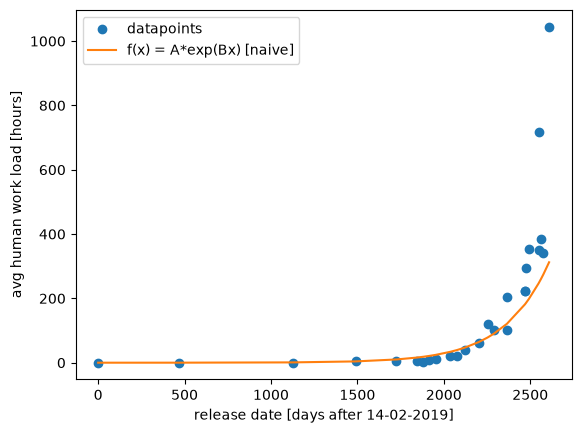

In [36]:
X = np.vstack([np.ones_like(xs), xs])

w = la.lstsq(X.T, np.log(ys), rcond=None)[0]

a = w[0]
B = w[1]

def f(x, a, B):
    return np.exp(a) * np.exp(B*x)

def plot(x, y, a, B):
    plt.figure()
    plt.plot(x, y, 'o', label='datapoints')
    plt.plot(x, f(x, a, B), label='f(x) = A*exp(Bx) [naive]')
    plt.xlabel('release date [days after 14-02-2019]')
    plt.ylabel('avg human work load [hours]')
    plt.legend()
    plt.show()

plot(xs, ys, a, B)


## Task 1.4.2

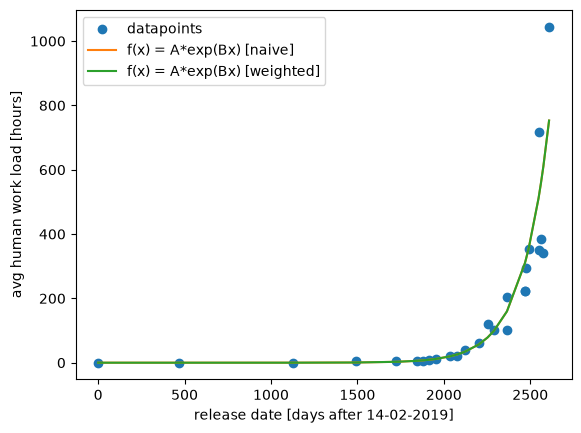

In [ ]:
D = np.diag(np.sqrt(ys))

w_2 = la.lstsq(D @ X.T, D @ np.log(ys))[0]

a_2 = w_2[0]
B_2 = w_2[1]


def plot_2(x, y, a, B, a_2, B_2):
    plt.figure()
    plt.plot(x, y, 'o', label='datapoints')
    plt.plot(x, f(x, a, B), label='f(x) = A*exp(Bx) [naive]')
    plt.plot(x, f(x, a_2, B_2), label='f(x) = A*exp(Bx) [weighted]')

    plt.xlabel('release date [days after 14-02-2019]')
    plt.ylabel('avg human work load [hours]')
    plt.legend()
    plt.show()

plot_2(xs, ys, a, B, a_2, B_2)